# Entrenamiento de XGBoost

**Maestría en Inteligencia Artificial MAIA**

**Proyecto - Desarrollo de Soluciones**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier` usando `train.csv` y `test.csv` procesados. La busqueda de hiperparametros se valida con `StratifiedGroupKFold` usando `subject_code` como grupo para evitar data leakage entre train y validation. La metrica principal es `f1_macro`, apropiada para este problema multiclase desbalanceado.

In [31]:
from pathlib import Path
import json
import warnings

import joblib
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS

try:
    from xgboost import XGBClassifier
except Exception as exc:
    raise ImportError(
        "No se pudo importar XGBoost. En macOS suele faltar el runtime OpenMP; "
        "instalalo con `brew install libomp` y vuelve a ejecutar el kernel."
    ) from exc

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

## Configuracion

Los identificadores de sujeto y grabacion se excluyen del entrenamiento para evitar fuga de informacion. Si se quiere comparar contra un modelo que use estas columnas, agregarlas explicitamente a `FEATURE_COLUMNS` despues de justificarlo.

In [32]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 20
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"

TRAIN_PATH, TEST_PATH, MODEL_DIR

(PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/train.csv'),
 PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/data/processed/test.csv'),
 PosixPath('/Users/joevargas/Documents/personal/Maestria Andes - IA/14_proyecto_desarrollo_soluciones/micro_proyecto/proyecto-desarrollo-de-soluciones-G5/models'))

## Carga de datos

In [33]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))

Train shape: (150272, 17)
Test shape:  (45207, 17)


,EEG_Fpz-Cz__delta_power_abs,EEG_Fpz-Cz__delta_power_rel,EEG_Fpz-Cz__theta_power_abs,EEG_Fpz-Cz__theta_power_rel,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__sigma_power_abs,EEG_Fpz-Cz__sigma_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__theta_alpha_ratio,EEG_Fpz-Cz__sef95,EEG_Fpz-Cz__spectral_entropy,y,recording_id,subject_code
0,441.49713,0.869095,27.724798,0.054577,10.516427,0.020702,4.884139,0.009615,20.179281,0.039723,41.981667,2.636332,20.25,0.595699,0,SC4481F0,48
1,485.16055,0.848066,44.572014,0.077912,13.932046,0.024353,4.607310,0.008054,15.736931,0.027508,34.823353,3.199244,7.50,0.540363,0,SC4481F0,48
2,431.59152,0.854248,33.038925,0.065394,11.134102,0.022038,6.312143,0.012494,21.599360,0.042752,38.763030,2.967363,13.25,0.524626,0,SC4481F0,48
3,510.90277,0.878044,32.257076,0.055437,10.797283,0.018556,5.808200,0.009982,21.244148,0.036510,47.317720,2.987518,12.25,0.515004,0,SC4481F0,48
4,622.32336,0.746474,48.513107,0.058191,24.586466,0.029491,23.989834,0.028776,127.950350,0.153476,25.311625,1.973163,44.25,0.692052,0,SC4481F0,48


y
0    49565
1    16445
2    53593
3    10579
4    20090
Name: train_count, dtype: int64

y
0    16386
1     5077
2    15539
3     2460
4     5745
Name: test_count, dtype: int64

## Preparacion de matrices

In [34]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

feature_columns = [
    column
    for column in train_df.columns
    if column not in [TARGET_COLUMN, *ID_COLUMNS]
]

X_train = train_df[feature_columns].copy()
X_test = test_df[feature_columns].copy()

# Los datos nuevos tienen y como nombres de clase. El map mantiene compatibilidad
# con CSV antiguos donde y estaba guardada como 0, 1, 2, 3, 4.
y_train_names = train_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(train_df[TARGET_COLUMN]).astype(str)
y_test_names = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

groups = train_df["subject_code"].astype(str).to_numpy()
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Numero de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
print(f"Numero de pacientes/grupos en train: {pd.Series(groups).nunique()}")
display(pd.Series(feature_columns, name="features"))

Numero de features: 14
Clases: ['W', 'N1', 'N2', 'N3', 'REM']
Numero de pacientes/grupos en train: 62


0       EEG_Fpz-Cz__delta_power_abs
1       EEG_Fpz-Cz__delta_power_rel
2       EEG_Fpz-Cz__theta_power_abs
3       EEG_Fpz-Cz__theta_power_rel
4       EEG_Fpz-Cz__alpha_power_abs
5       EEG_Fpz-Cz__alpha_power_rel
6       EEG_Fpz-Cz__sigma_power_abs
7       EEG_Fpz-Cz__sigma_power_rel
8        EEG_Fpz-Cz__beta_power_abs
9        EEG_Fpz-Cz__beta_power_rel
10    EEG_Fpz-Cz__delta_alpha_ratio
11    EEG_Fpz-Cz__theta_alpha_ratio
12                EEG_Fpz-Cz__sef95
13     EEG_Fpz-Cz__spectral_entropy
Name: features, dtype: object

## Busqueda de hiperparametros con validacion cruzada

La busqueda usa `RandomizedSearchCV` con CV estratificada por clase y agrupada por `subject_code`. Asi, todas las epocas de un mismo paciente quedan completas en train o en validation dentro de cada fold. El mejor modelo se selecciona por `f1_macro`.

In [35]:
base_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 1.5, 2.0],
}

cv = StratifiedGroupKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=N_ITER_SEARCH,
    scoring=SCORING,
    cv=cv,
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)

search.fit(X_train, y_train, groups=groups, sample_weight=sample_weights)

print(f"Mejor {SCORING} CV: {search.best_score_:.4f}")
print("Mejores hiperparametros:")
display(search.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  16.4s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  16.4s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  16.8s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  16.7s
[CV] END colsample_bytree=0.7, gamma=1.0, learning_rate=0.08, max_depth=8, min_child_weight=1, n_estimators=300, reg_alpha=0.1, reg_lambda=1.0, subsample=0.9; total time=  17.1s
[CV] END colsample_bytree=0.8, gamma=0, learning

{'subsample': 0.9,
 'reg_lambda': 1.5,
 'reg_alpha': 0,
 'n_estimators': 700,
 'min_child_weight': 3,
 'max_depth': 3,
 'learning_rate': 0.05,
 'gamma': 0.5,
 'colsample_bytree': 0.7}

In [36]:
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cv_summary_columns = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]
display(cv_results[cv_summary_columns].head(10))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
12,1,0.658647,0.021366,0.718659,0.004103,"{'subsample': 0.9, 'reg_lambda': 1.5, 'reg_alp..."
6,2,0.657568,0.022303,0.733592,0.003740,"{'subsample': 0.7, 'reg_lambda': 2.0, 'reg_alp..."
18,3,0.656901,0.022123,0.722046,0.004097,"{'subsample': 0.9, 'reg_lambda': 0.5, 'reg_alp..."
16,4,0.656542,0.021509,0.714701,0.004613,"{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alp..."
11,5,0.656246,0.022784,0.715471,0.004280,"{'subsample': 0.9, 'reg_lambda': 1.5, 'reg_alp..."
13,6,0.655563,0.022980,0.728957,0.004151,"{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alp..."
15,7,0.654780,0.023101,0.735696,0.003785,"{'subsample': 1.0, 'reg_lambda': 0.5, 'reg_alp..."
5,8,0.654085,0.022771,0.747071,0.003475,"{'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alp..."
14,9,0.653316,0.023010,0.744210,0.004190,"{'subsample': 0.7, 'reg_lambda': 1.0, 'reg_alp..."
3,10,0.653095,0.022559,0.706797,0.004970,"{'subsample': 0.9, 'reg_lambda': 2.0, 'reg_alp..."


## Evaluacion en test

In [37]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
kappa = cohen_kappa_score(y_test, y_pred)

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    y_pred,
    labels=np.arange(len(class_labels)),
    zero_division=0,
)

metrics = {
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "cohens_kappa": kappa,
    "best_cv_macro_f1": search.best_score_,
    "best_params": search.best_params_,
}

per_class_metrics = pd.DataFrame(
    {
        "class": class_labels,
        "precision_per_class": precision,
        "recall_per_class": recall,
        "f1_per_class": f1,
        "support": support,
    }
)

display(pd.Series(metrics, name="value"))
display(per_class_metrics)
print(classification_report(y_test, y_pred, target_names=[str(label) for label in class_labels], zero_division=0))

accuracy                                                      0.675714
macro_f1                                                      0.618627
balanced_accuracy                                             0.667597
cohens_kappa                                                  0.566791
best_cv_macro_f1                                              0.658647
best_params          {'subsample': 0.9, 'reg_lambda': 1.5, 'reg_alp...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.298882,0.426630,0.351509,5077
1,N1,0.900436,0.638458,0.747148,15539
2,N2,0.547261,0.917886,0.685697,2460
3,N3,0.441056,0.563969,0.494997,5745
4,REM,0.837880,0.791041,0.813787,16386


              precision    recall  f1-score   support

           W       0.30      0.43      0.35      5077
          N1       0.90      0.64      0.75     15539
          N2       0.55      0.92      0.69      2460
          N3       0.44      0.56      0.49      5745
         REM       0.84      0.79      0.81     16386

    accuracy                           0.68     45207
   macro avg       0.61      0.67      0.62     45207
weighted avg       0.73      0.68      0.69     45207



## Matriz de confusion

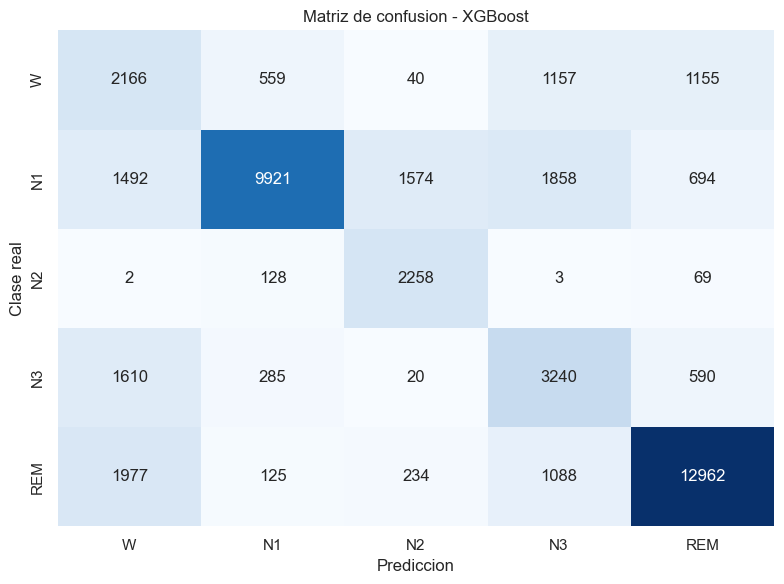

,W,N1,N2,N3,REM
W,2166,559,40,1157,1155
N1,1492,9921,1574,1858,694
N2,2,128,2258,3,69
N3,1610,285,20,3240,590
REM,1977,125,234,1088,12962


In [38]:
conf_matrix = confusion_matrix(y_test, y_pred, labels=np.arange(len(class_labels)))
conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Matriz de confusion - XGBoost")
plt.xlabel("Prediccion")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()

display(conf_matrix_df)

## Importancia de variables

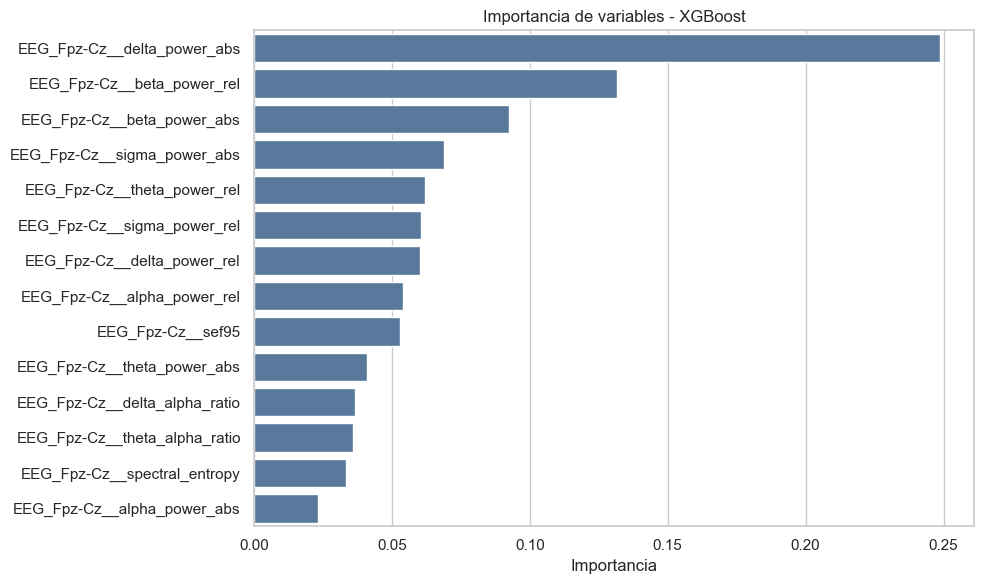

,feature,importance
0,EEG_Fpz-Cz__delta_power_abs,0.248620
9,EEG_Fpz-Cz__beta_power_rel,0.131587
8,EEG_Fpz-Cz__beta_power_abs,0.092322
6,EEG_Fpz-Cz__sigma_power_abs,0.068703
3,EEG_Fpz-Cz__theta_power_rel,0.061881
7,EEG_Fpz-Cz__sigma_power_rel,0.060403
1,EEG_Fpz-Cz__delta_power_rel,0.060258
5,EEG_Fpz-Cz__alpha_power_rel,0.054030
12,EEG_Fpz-Cz__sef95,0.052834
2,EEG_Fpz-Cz__theta_power_abs,0.040805


In [39]:
feature_importance = pd.DataFrame(
    {
        "feature": feature_columns,
        "importance": best_model.feature_importances_,
    }
).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x="importance", y="feature", color="#4C78A8")
plt.title("Importancia de variables - XGBoost")
plt.xlabel("Importancia")
plt.ylabel("")
plt.tight_layout()
plt.show()

display(feature_importance)

In [40]:
best_model.save_model("best-xgboost-model.json")

In [43]:
info = {
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "balanced_accuracy": balanced_acc,
    "cohens_kappa": kappa,
    "best_cv_macro_f1": search.best_score_,
    "best_params": search.best_params_,
}

with open("model_info.json", "w") as f:
    json.dump(info, f, indent=4)